# E1 · Pronóstico del Índice de Costo del Taco
**Observatorio Antojo Colima** · Avlix Eduardo Jiménez Cuevas · Análisis Estadístico

**Pregunta de E1:** ¿cuánto costará la canasta de insumos de una taquería en los próximos meses, y con qué incertidumbre?

Serie: `data/oro/indice_costo_taco.csv`, índice mensual de 8 insumos del SNIIM con pesos iguales (base promedio 2021 = 100).
Las funciones de los modelos están en `pipeline/pronostico.py`: el mismo código que usa este cuaderno es el que corre cada día en GitHub Actions y publica el pronóstico en el tablero.

In [1]:
import sys
import warnings
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "laboratorio" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, ccf, kpss

from pipeline.pronostico import HORIZONTE, PRUEBA, ajustar, comparar, pronosticar, serie_indice

DATA = RAIZ / "data"
AZUL, NARANJA, GRIS, VERDE, VIOLETA = "#2a78d6", "#eb6834", "#8a8984", "#1baf7a", "#6250d6"
COLORES = {"SES": AZUL, "Holt": VERDE, "Holt-Winters": VIOLETA, "ARIMA": NARANJA}
plt.rcParams.update(
    {"figure.figsize": (10, 3.6), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25}
)

serie = serie_indice(DATA)
indice = pd.read_csv(DATA / "oro" / "indice_costo_taco.csv")
print(f"{len(serie)} meses completos: {serie.index[0]:%Y-%m} a {serie.index[-1]:%Y-%m}")
print(f"(el índice tiene {len(indice)} meses; el último se excluye si el mes todavía no termina)")

79 meses completos: 2020-04 a 2026-10
(el índice tiene 80 meses; el último se excluye si el mes todavía no termina)


## 1. Caracterización de la serie

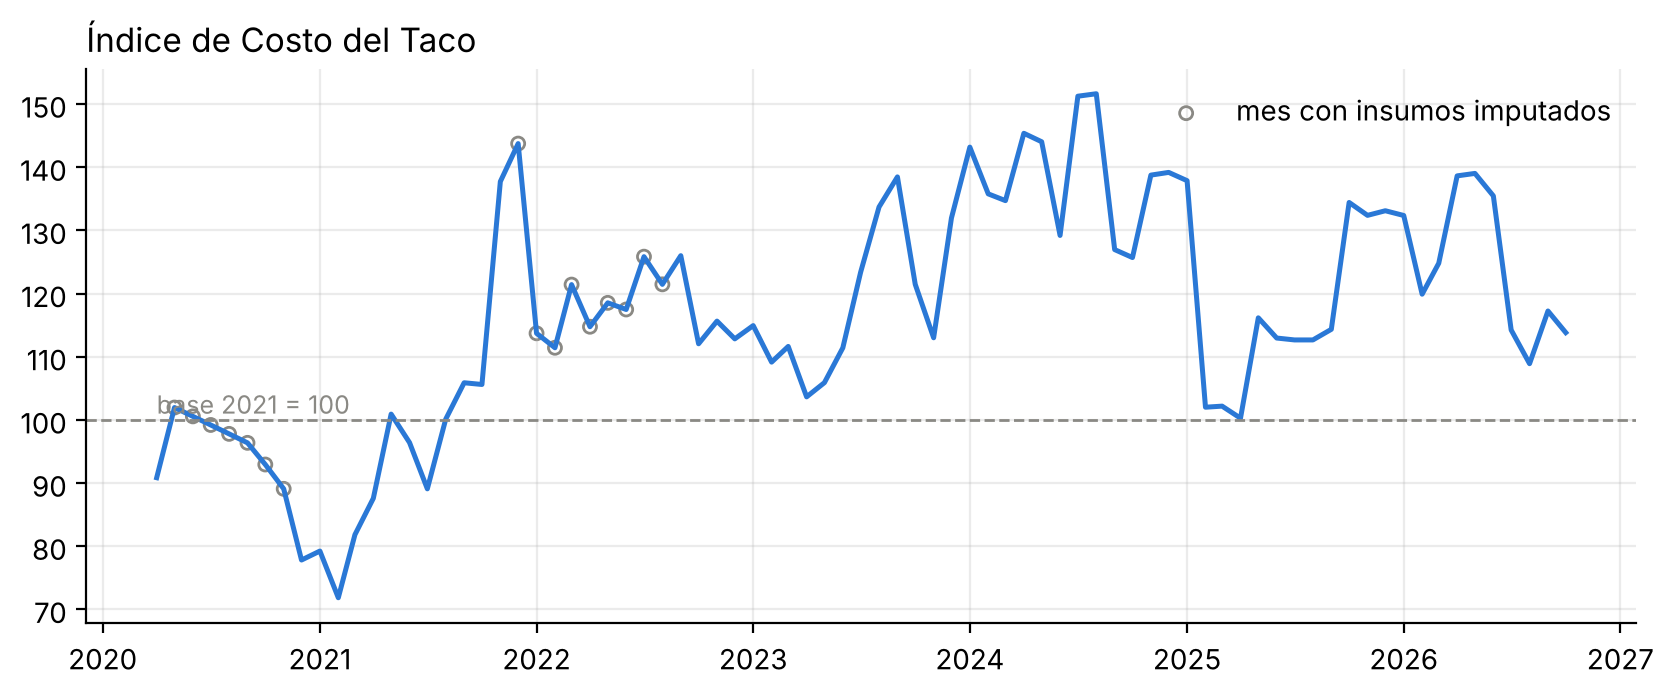

media 116.4 · desviación 18.2 · CV 15.6 % · mín 71.8 (2021-02) · máx 151.6 (2024-08)
cambio mensual: mediana -0.3 %, el 90 % de los meses entre -13.1 % y +16.0 %
asimetría -0.20 · curtosis -0.52


In [2]:
fig, ax = plt.subplots()
ax.plot(serie.index, serie, color=AZUL, lw=1.8)
ax.axhline(100, color=GRIS, lw=1, ls="--")
ax.text(serie.index[0], 101, "base 2021 = 100", color=GRIS, fontsize=9)
imp = (
    indice.set_index(pd.PeriodIndex(indice["mes"], freq="M").to_timestamp())["insumos_imputados"].reindex(serie.index).fillna("")
)
ax.scatter(serie.index[imp != ""], serie[imp != ""], s=22, facecolors="none", edgecolors=GRIS, label="mes con insumos imputados")
ax.set_title("Índice de Costo del Taco", loc="left")
ax.legend(frameon=False)
plt.show()

desc = serie.describe()
cv = desc["std"] / desc["mean"] * 100
var_m = serie.pct_change() * 100
print(
    f"media {desc['mean']:.1f} · desviación {desc['std']:.1f} · CV {cv:.1f} % · "
    f"mín {desc['min']:.1f} ({serie.idxmin():%Y-%m}) · máx {desc['max']:.1f} ({serie.idxmax():%Y-%m})"
)
print(
    f"cambio mensual: mediana {var_m.median():+.1f} %, "
    f"el 90 % de los meses entre {var_m.quantile(0.05):+.1f} % y {var_m.quantile(0.95):+.1f} %"
)
print(f"asimetría {stats.skew(serie):.2f} · curtosis {stats.kurtosis(serie):.2f}")

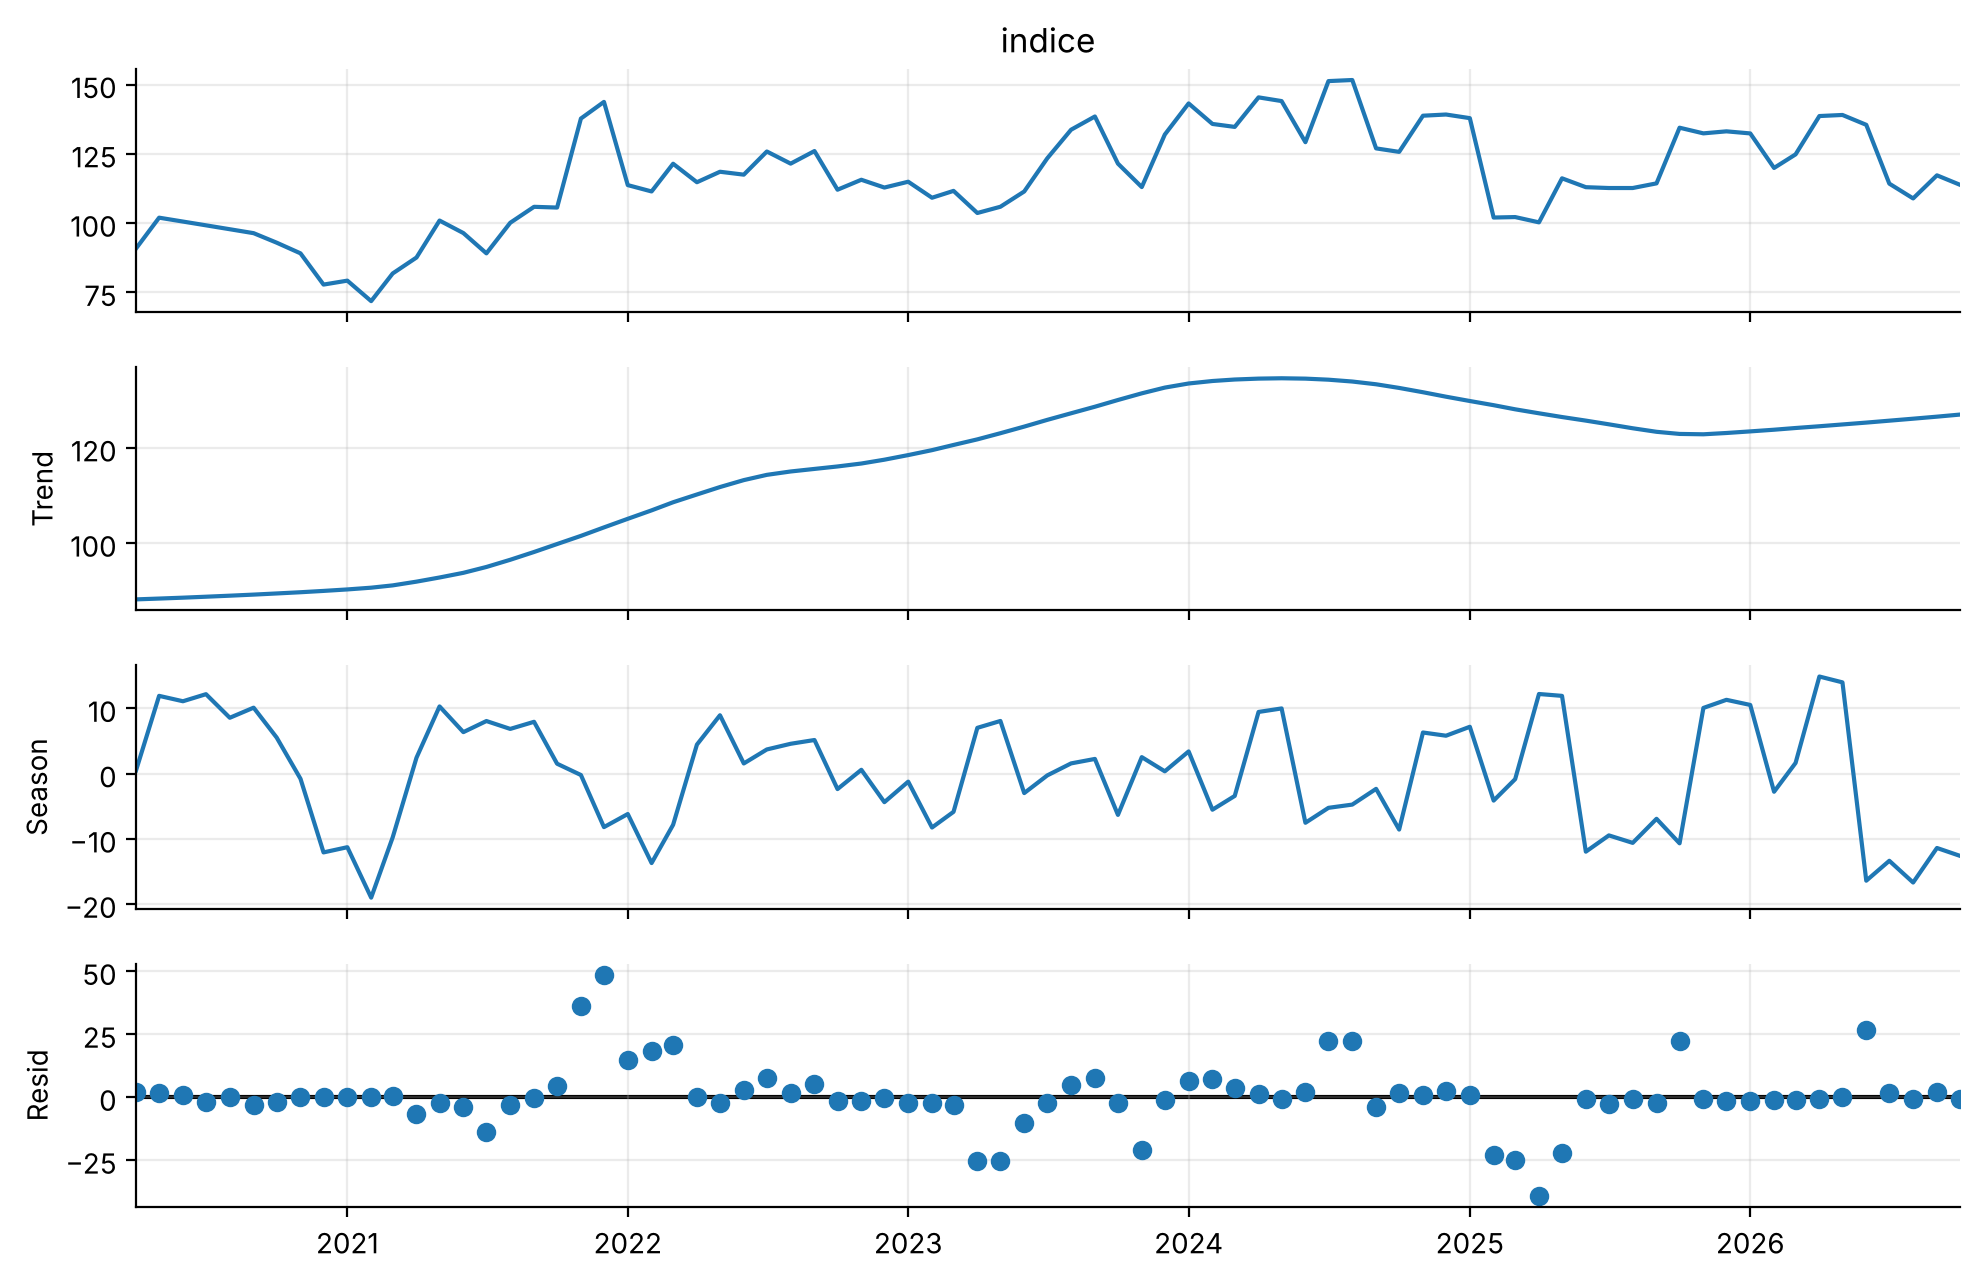

Fuerza de la tendencia: 0.56 · fuerza de la estacionalidad: 0.00  (0 = nada, 1 = domina)
Efecto estacional promedio por mes (puntos del índice): {1: 0.4, 2: -8.9, 3: -4.3, 4: 7.3, 5: 10.7, 6: -2.8, 7: -0.6, 8: -1.5, 9: 0.7, 10: -4.8, 11: 3.1, 12: -1.2}


In [3]:
stl = STL(serie, period=12, robust=True).fit()
fig = stl.plot()
fig.set_size_inches(10, 6.5)
plt.tight_layout()
plt.show()

fuerza_tend = max(0, 1 - np.var(stl.resid) / np.var(stl.trend + stl.resid))
fuerza_est = max(0, 1 - np.var(stl.resid) / np.var(stl.seasonal + stl.resid))
print(f"Fuerza de la tendencia: {fuerza_tend:.2f} · fuerza de la estacionalidad: {fuerza_est:.2f}  (0 = nada, 1 = domina)")
estacional = stl.seasonal.groupby(stl.seasonal.index.month).mean()
print("Efecto estacional promedio por mes (puntos del índice):", {m: round(v, 1) for m, v in estacional.items()})

**Lectura.** La descomposición STL (aditiva y robusta a atípicos; abajo se justifica aditiva contra multiplicativa) separa la serie en tendencia, estacionalidad de 12 meses y residuo. La **fuerza** mide qué fracción de la variación explica cada componente (Hyndman y Athanasopoulos). Si la estacionalidad es débil, un modelo estacional como Holt-Winters agrega parámetros sin ganar precisión; lo comprobamos con el error de prueba en la sección 4.

### ¿Modelo aditivo o multiplicativo?

* **Aditivo** (Y = T + S + R): la estacionalidad suma siempre los mismos puntos, sin importar el nivel.
* **Multiplicativo** (Y = T × S × R): la estacionalidad es un porcentaje del nivel; cuando la serie sube, las oscilaciones crecen.

La forma de decidir es ver si la **amplitud** crece con el **nivel**. Lo medimos año por año y comparamos las dos descomposiciones clásicas:

In [4]:
from statsmodels.tsa.seasonal import seasonal_decompose

anual = pd.DataFrame(
    {
        "nivel promedio": serie.groupby(serie.index.year).mean(),
        "rango (máx - mín)": serie.groupby(serie.index.year).agg(lambda x: x.max() - x.min()),
        "meses": serie.groupby(serie.index.year).size(),
    }
).round(1)
completos = anual[anual["meses"] >= 10]
r_nivel_rango = completos["nivel promedio"].corr(completos["rango (máx - mín)"])
print(f"Correlación entre nivel y amplitud (años con 10+ meses): {r_nivel_rango:.2f}")

aditivo = seasonal_decompose(serie, model="additive", period=12)
multiplicativo = seasonal_decompose(serie, model="multiplicative", period=12)
resid_mult_puntos = (multiplicativo.resid - 1) * multiplicativo.trend
print(f"Desviación del residuo: aditivo {aditivo.resid.std():.2f} puntos · multiplicativo {resid_mult_puntos.std():.2f} puntos")
anual

Correlación entre nivel y amplitud (años con 10+ meses): -0.73
Desviación del residuo: aditivo 8.83 puntos · multiplicativo 8.76 puntos


,nivel promedio,rango (máx - mín),meses
mes,,,
2020,94.1,24.1,9
2021,100.0,71.9,12
2022,117.6,14.6,12
2023,118.2,34.8,12
2024,138.8,25.9,12
2025,117.6,37.6,12
2026,124.4,30.1,10


**Decisión: aditivo.** Si la serie fuera multiplicativa, los años más caros tendrían oscilaciones más grandes. Pasa lo contrario: la correlación entre nivel y amplitud es **negativa (−0.73)**. El año con más variación fue 2021 (rango de 72 puntos con nivel 100), mientras 2024, el año más caro (nivel 139), tuvo un rango de solo 26. Además, los dos residuos son prácticamente iguales (8.8 puntos), así que el multiplicativo no explica nada extra y es más difícil de leer. Las oscilaciones vienen de **choques de oferta** (heladas, escasez), no de un porcentaje del nivel. Por eso la STL de arriba, que es aditiva, es la adecuada.

## 2. Estacionariedad

In [5]:
def pruebas(s, nombre):
    warnings.simplefilter("ignore")  # KPSS avisa cuando el p real es mayor que 0.10 (fuera de su tabla)
    adf = adfuller(s.dropna(), autolag="AIC")
    k = kpss(s.dropna(), regression="c", nlags="auto")
    return {
        "serie": nombre,
        "ADF estadístico": adf[0],
        "ADF p": adf[1],
        "KPSS estadístico": k[0],
        "KPSS p": k[1],
        "conclusión": "estacionaria"
        if adf[1] < 0.05 and k[1] > 0.05
        else ("no estacionaria" if adf[1] >= 0.05 and k[1] <= 0.05 else "mixta"),
    }


pd.DataFrame(
    [pruebas(serie, "nivel"), pruebas(serie.diff(), "primera diferencia"), pruebas(serie.diff(12), "diferencia estacional (12)")]
).round(3)

,serie,ADF estadístico,ADF p,KPSS estadístico,KPSS p,conclusión
0,nivel,-2.169,0.218,0.718,0.012,no estacionaria
1,primera diferencia,-8.536,0.000,0.132,0.100,estacionaria
2,diferencia estacional (12),-4.083,0.001,0.223,0.100,estacionaria


**Cómo se leen.** Las dos pruebas tienen hipótesis opuestas, por eso se usan juntas:

* **ADF**: H₀ = la serie tiene raíz unitaria (no es estacionaria). p < 0.05 → se rechaza → estacionaria.
* **KPSS**: H₀ = la serie es estacionaria. p < 0.05 → se rechaza → no estacionaria. (statsmodels acota el p de KPSS entre 0.01 y 0.10.)

Si en nivel no es estacionaria y en primera diferencia sí, el modelo ARIMA necesita **d = 1**, que es lo que elige `pipeline/pronostico.py` de forma automática con la ADF.

## 3. Dependencia: autocorrelación y correlación cruzada

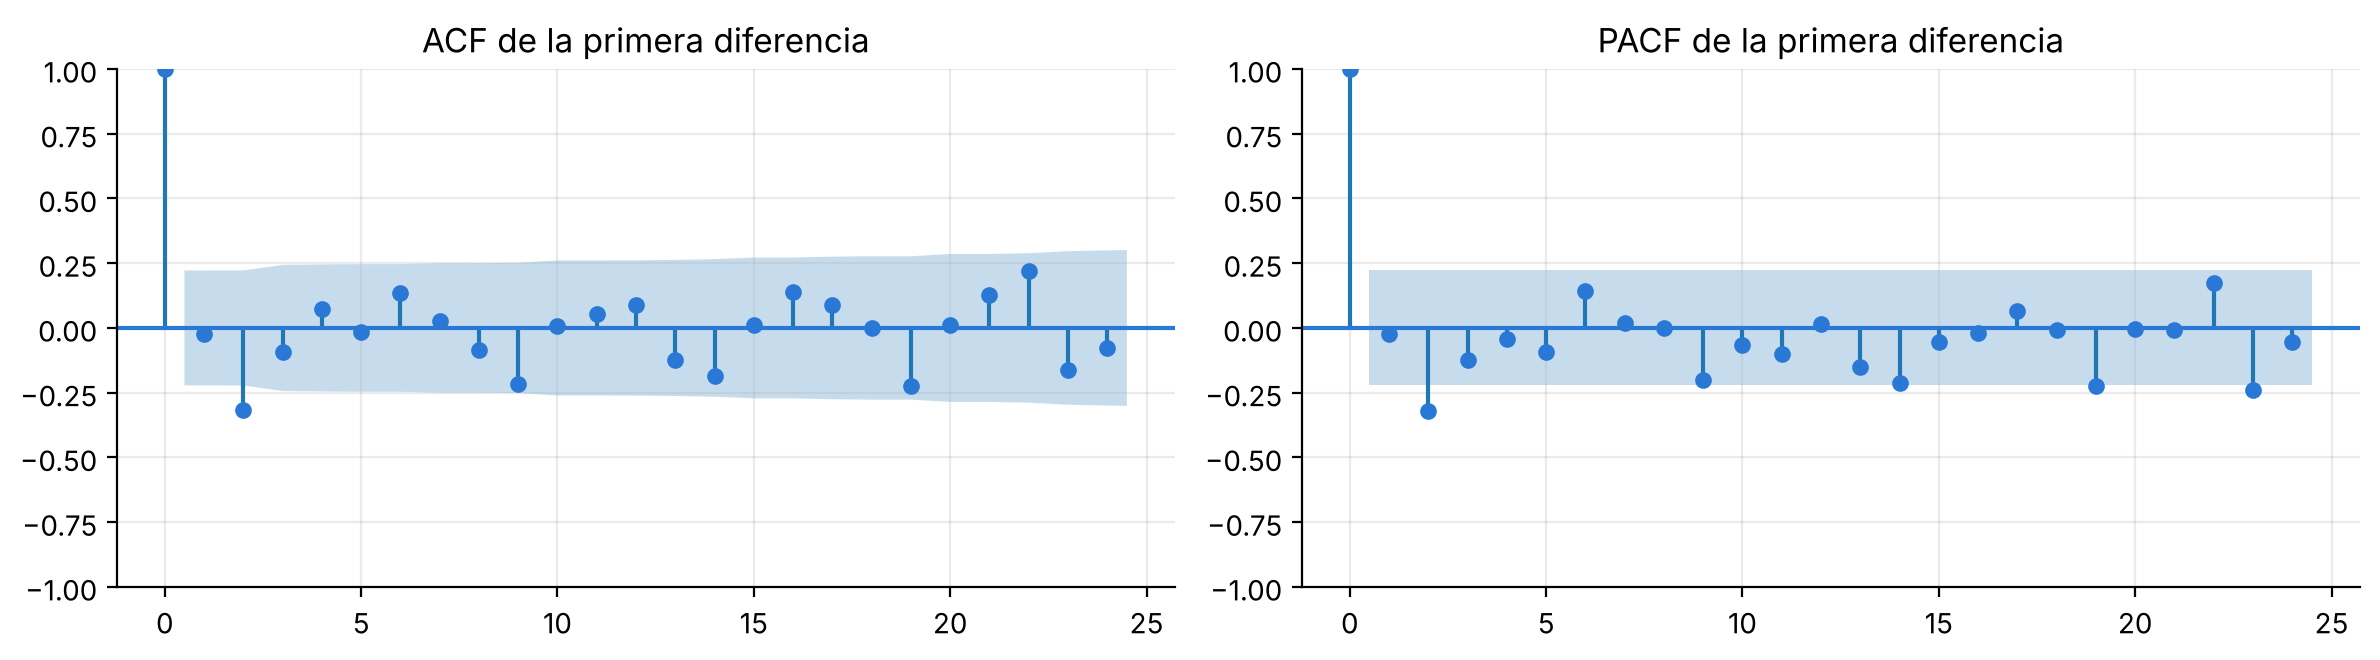

Banda de significancia ±0.22. Rezagos significativos en la ACF: [2, 9]
ACF rezagos 1 a 4: [-0.02, -0.32, -0.1, 0.08]


In [6]:
d1 = serie.diff().dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
plot_acf(d1, lags=24, ax=axes[0], color=AZUL, title="ACF de la primera diferencia")
plot_pacf(d1, lags=24, ax=axes[1], color=AZUL, method="ywm", title="PACF de la primera diferencia")
plt.tight_layout()
plt.show()
banda = 1.96 / np.sqrt(len(d1))
acf_vals = pd.Series([d1.autocorr(k) for k in range(1, 13)], index=range(1, 13))
print(
    f"Banda de significancia ±{banda:.2f}. Rezagos significativos en la ACF: {[k for k, v in acf_vals.items() if abs(v) > banda]}"
)
print("ACF rezagos 1 a 4:", acf_vals.iloc[:4].round(2).tolist())

**Lectura.** Sobre la primera diferencia, el rezago 1 casi no pesa y el **rezago 2 sale negativo y significativo**: un alza suele ir seguida de una corrección dos meses después. La PACF corta después del rezago 2, lo que apunta a un **AR(2) sobre la diferencia**, es decir, un ARIMA(2, 1, 0). No hay pico en el rezago 12, lo cual confirma que la estacionalidad es débil. ARIMA se elige al final por AIC entre p, q ∈ {0, 1, 2}, y la búsqueda automática llega justamente a (2, 1, 0).

### Correlación cruzada: ¿algún insumo se adelanta al índice?

Si el precio de un insumo sube **antes** que la canasta completa, sería una señal temprana útil para el taquero. Calculamos la correlación entre el cambio del insumo en el mes *t* y el cambio del índice **sin ese insumo** en el mes *t + k* (quitarlo evita que se correlacione consigo mismo).

In [7]:
precios = pd.read_csv(DATA / "oro" / "precios_mensuales.csv")
tabla = precios.pivot(index="mes", columns="insumo", values="precio_mediana")
tabla.index = pd.PeriodIndex(tabla.index, freq="M").to_timestamp()
tabla = tabla.reindex(serie.index).dropna()
base = tabla[tabla.index.year == 2021].mean()
filas = []
for insumo in tabla.columns:
    resto = (tabla.drop(columns=insumo) / base.drop(insumo) * 100).mean(axis=1)
    x, y = np.log(tabla[insumo]).diff().dropna(), np.log(resto).diff().dropna()
    c = ccf(x, y, adjusted=False, nlags=4)  # c[k] = corr(x_t, y_{t+k})
    filas.append({"insumo": insumo, **{f"k={k}": c[k] for k in range(4)}})
cruz = pd.DataFrame(filas).set_index("insumo").round(2)
banda = 1.96 / np.sqrt(len(x))
print(f"Banda de significancia ±{banda:.2f}  (k = meses que el insumo se adelanta al resto de la canasta)")
cruz

Banda de significancia ±0.22  (k = meses que el insumo se adelanta al resto de la canasta)


,k=0,k=1,k=2,k=3
insumo,,,,
aguacate,-0.05,0.01,0.14,-0.11
cebolla,0.13,-0.03,-0.06,0.06
chile_jalapeno,0.49,-0.07,-0.28,-0.03
chile_serrano,0.34,-0.15,-0.18,-0.07
limon,-0.18,-0.10,0.09,0.11
papa,0.00,0.00,0.12,-0.07
tomate_saladette,0.45,0.23,-0.22,-0.10
tomate_verde,0.55,0.06,-0.24,-0.02


**Lectura** (banda ±0.22):

* En el **mismo mes (k = 0)**, los tomates y los chiles se mueven con el resto de la canasta (0.34 a 0.55). El **aguacate, el limón y la papa no** (|r| ≤ 0.18): van por su cuenta, lo mismo que mostró el PCA del cuaderno de limpieza.
* **Adelanto (k = 1)**: solo el **tomate saladette** sale de la banda, y apenas (0.23). Con 8 insumos × 3 rezagos se esperaría al menos un resultado así por azar, así que **no lo usamos todavía como alerta temprana**; se volverá a probar con más meses en E2.
* En **k = 2**, el jalapeño y el tomate verde dan correlaciones negativas (−0.24 a −0.28): después de un alza, el resto de la canasta tiende a bajar dos meses después (rebote). Es consistente con el rezago 2 significativo de la ACF y con el AR(2) que elige ARIMA.

Conclusión: el índice se pronostica con **su propia historia**, que es lo que hacen los cuatro modelos.

## 4. Cuatro modelos y selección por error

* **SES** (suavizamiento exponencial simple): solo nivel; pronóstico plano.
* **Holt** con tendencia **amortiguada**: nivel y tendencia, que se va aplanando (evita extrapolar subidas para siempre).
* **Holt-Winters**: nivel, tendencia amortiguada y estacionalidad aditiva de 12 meses.
* **ARIMA(p, d, q)**: d por la prueba ADF; p y q ∈ {0, 1, 2} por el menor AIC.

**Validación fuera de muestra**: se entrena con todo menos los últimos 12 meses y se pronostican esos 12 sin verlos. Se elige el de menor **RMSE** (penaliza más los errores grandes, que son los que le cuestan al taquero) y el MAE desempata.

### Justificación de p, d y q para ARIMA

* **d = 1**: la ADF no rechaza la raíz unitaria en nivel y sí en la primera diferencia (sección 2).
* **p y q**: la PACF corta en el rezago 2 y la ACF tiene su pico significativo en el rezago 2 (sección 3), lo que sugiere un AR(2) o un MA(2) sobre la diferencia. Lo decide el **AIC**, que premia el ajuste y castiga cada parámetro de más:

In [8]:
import itertools

from statsmodels.tsa.statespace.sarimax import SARIMAX

entrenamiento_aic = serie.iloc[:-PRUEBA]
filas = []
for p, q in itertools.product(range(3), range(3)):
    m = SARIMAX(entrenamiento_aic, order=(p, 1, q)).fit(disp=False)
    filas.append({"orden (p, d, q)": f"({p}, 1, {q})", "AIC": m.aic, "parámetros": p + q})
aic = pd.DataFrame(filas).sort_values("AIC").reset_index(drop=True)
aic["Δ AIC contra el mejor"] = aic["AIC"] - aic["AIC"].min()
aic.round(1).head(6)

,"orden (p, d, q)",AIC,parámetros,Δ AIC contra el mejor
0,"(2, 1, 0)",504.6,2,0.0
1,"(0, 1, 2)",505.1,2,0.4
2,"(2, 1, 1)",505.8,3,1.2
3,"(1, 1, 2)",506.8,3,2.1
4,"(1, 1, 1)",507.1,2,2.5
5,"(0, 1, 0)",507.7,0,3.1


**Lectura.** El menor AIC es **ARIMA(2, 1, 0)**, que coincide con la PACF (corte en 2). El MA(2) (0, 1, 2) queda a menos de 1 punto: según la regla usual (Δ AIC < 2), los dos son equivalentes en ajuste, tienen los mismos parámetros y cuentan la misma historia (corrección a 2 meses). Nos quedamos con el AR(2) porque es el que señalan juntos la PACF y el AIC, y lo confirma su error fuera de muestra en la tabla siguiente.

In [9]:
tabla_err, predicciones = comparar(serie)
entrenamiento, prueba = serie.iloc[:-PRUEBA], serie.iloc[-PRUEBA:]
print(
    f"Entrenamiento: {entrenamiento.index[0]:%Y-%m} a {entrenamiento.index[-1]:%Y-%m} ({len(entrenamiento)} meses) · "
    f"prueba: {prueba.index[0]:%Y-%m} a {prueba.index[-1]:%Y-%m}"
)
tabla_err[["modelo", "mae", "rmse", "mape", "detalle", "elegido"]]

Entrenamiento: 2020-04 a 2025-10 (67 meses) · prueba: 2025-11 a 2026-10


,modelo,mae,rmse,mape,detalle,elegido
0,ARIMA,9.459,10.714,7.803,"orden (2, 1, 0)",True
1,SES,9.338,11.876,7.909,,False
2,Holt,9.339,11.945,7.918,,False
3,Holt-Winters,12.195,15.019,10.258,,False


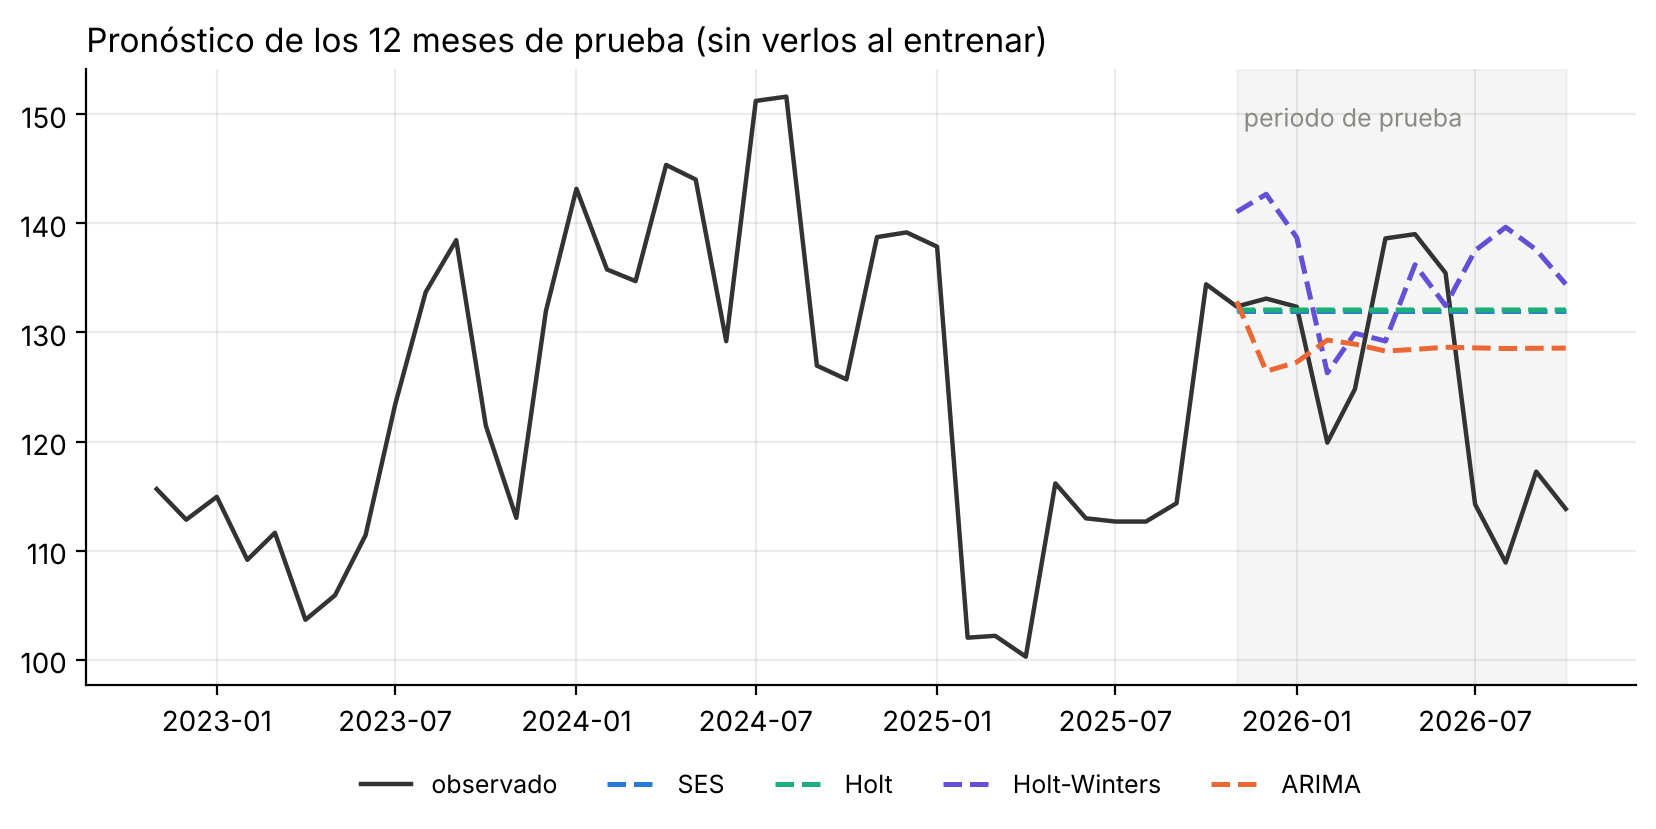

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(serie.index[-48:], serie.iloc[-48:], color="#333", lw=1.6, label="observado")
for nombre, p in predicciones.items():
    ax.plot(p.index, p["valor"], color=COLORES[nombre], lw=1.8, ls="--", label=nombre)
ax.axvspan(prueba.index[0], prueba.index[-1], color=GRIS, alpha=0.08)
ax.text(prueba.index[0], ax.get_ylim()[1] * 0.98, " periodo de prueba", va="top", color=GRIS, fontsize=9)
ax.set_title("Pronóstico de los 12 meses de prueba (sin verlos al entrenar)", loc="left")
ax.legend(frameon=False, ncol=5, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

In [11]:
parametros = []
for nombre in ["SES", "Holt", "Holt-Winters", "ARIMA"]:
    m = ajustar(nombre, entrenamiento)
    p = pd.Series(np.asarray(m.params), index=m.param_names)
    nombres = {
        "smoothing_level": "α (nivel)",
        "smoothing_trend": "β (tendencia)",
        "damping_trend": "φ (amortiguamiento)",
        "smoothing_seasonal": "γ (estacional)",
    }
    if nombre == "ARIMA":
        texto = ", ".join(f"{k} = {v:.3f}" for k, v in p.items())
    else:
        texto = ", ".join(f"{nombres[k]} = {p[k]:.3f}" for k in nombres if k in p.index)
    parametros.append({"modelo": nombre, "parámetros": texto})
pd.set_option("display.max_colwidth", 200)
pd.DataFrame(parametros)

,modelo,parámetros
0,SES,α (nivel) = 0.877
1,Holt,"α (nivel) = 0.884, β (tendencia) = 0.000, φ (amortiguamiento) = 0.800"
2,Holt-Winters,"α (nivel) = 1.000, β (tendencia) = 0.000, φ (amortiguamiento) = 0.818, γ (estacional) = 0.000"
3,ARIMA,"ar.L1 = -0.051, ar.L2 = -0.323, sigma2 = 111.451"


**Lectura de los parámetros.** En los modelos de suavizamiento, α cercano a 1 quiere decir que el modelo casi solo toma en cuenta el último mes: la serie se comporta como una **caminata aleatoria**, lo típico en precios. β ≈ 0 indica que no hay una tendencia estable que valga la pena seguir, y φ < 1 la aplana. Por eso Holt queda casi igual que SES. En Holt-Winters, γ = 0 quiere decir que el patrón estacional que estimó al inicio nunca se actualiza: no encontró estacionalidad real que aprender. En ARIMA, el coeficiente AR del rezago 2 es negativo: es el efecto de rebote que vimos en la ACF.

## 5. Diagnóstico de residuos del modelo elegido

Modelo elegido: ARIMA (2, 1, 0)
Media de residuos 0.38 (debe ser ≈ 0) · desviación 10.33
Ljung-Box (H0: residuos sin autocorrelación):
    lb_stat  lb_pvalue
6     4.079      0.666
12   10.272      0.592
Shapiro-Wilk (H0: normalidad): W = 0.970, p = 0.064


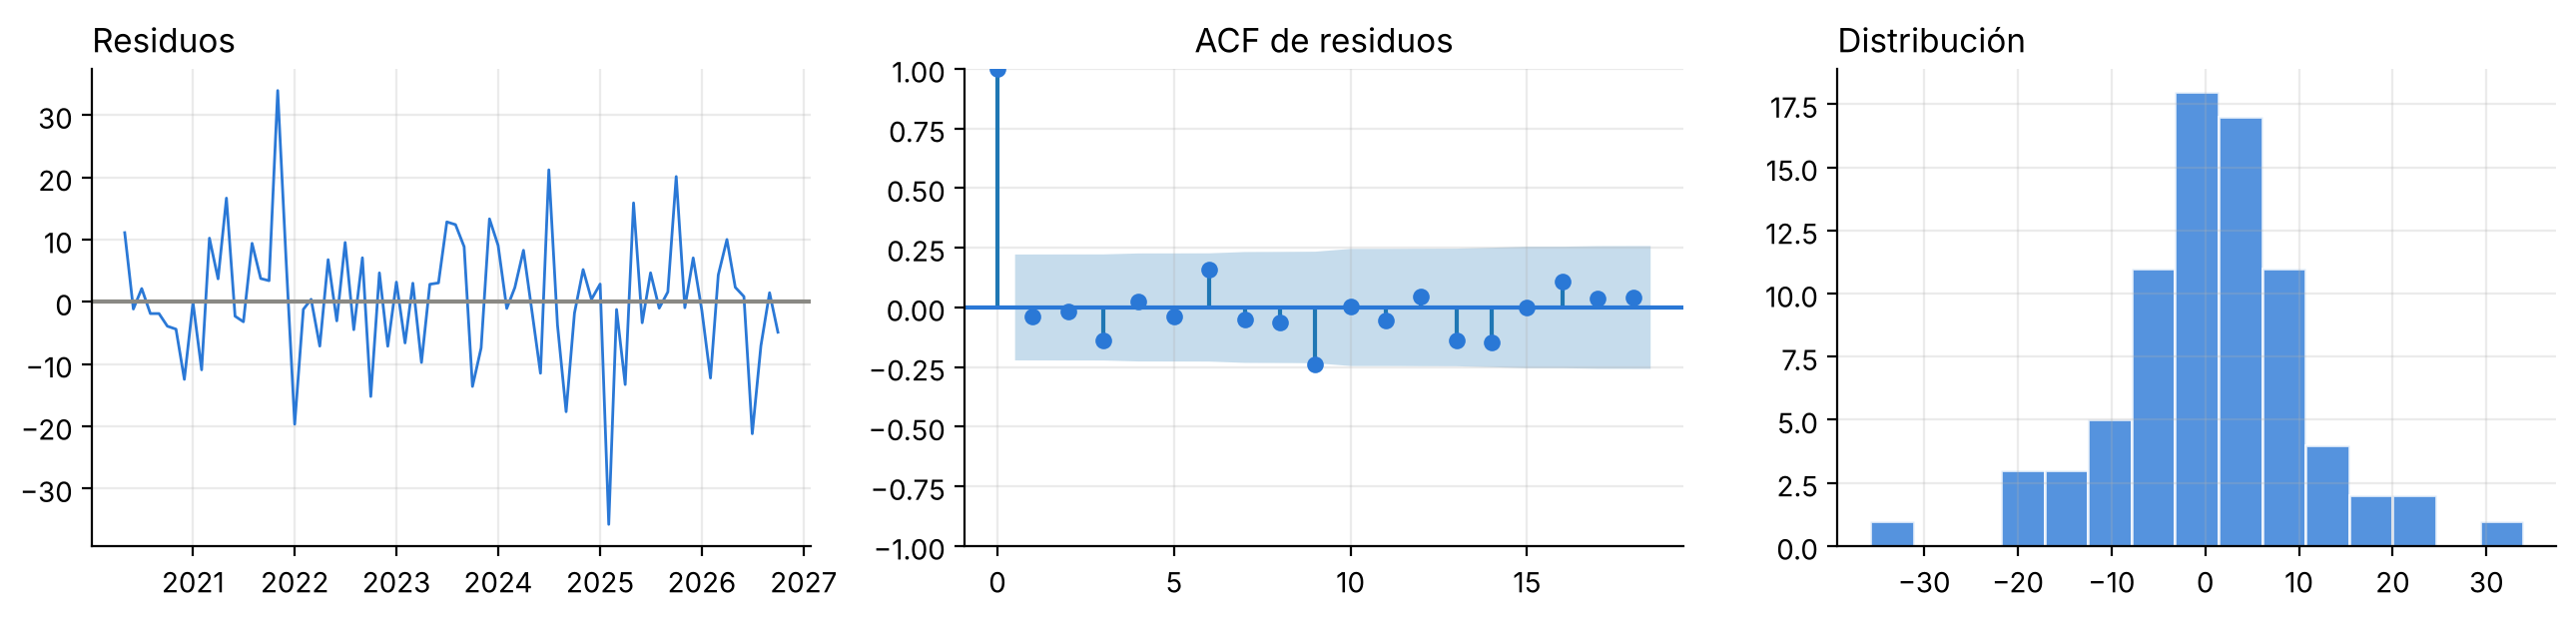

In [12]:
elegido = tabla_err.loc[tabla_err["elegido"], "modelo"].iloc[0]
modelo = ajustar(elegido, serie)
resid = pd.Series(np.asarray(modelo.resid), index=serie.index)
resid = resid.iloc[
    (modelo.model.order[1] if elegido == "ARIMA" else 0) :
]  # el primer residuo de un ARIMA diferenciado no es informativo

lb = acorr_ljungbox(resid, lags=[6, 12], return_df=True)
sw = stats.shapiro(resid)
print(f"Modelo elegido: {elegido}" + (f" {modelo.model.order}" if elegido == "ARIMA" else ""))
print(f"Media de residuos {resid.mean():.2f} (debe ser ≈ 0) · desviación {resid.std():.2f}")
print("Ljung-Box (H0: residuos sin autocorrelación):")
print(lb.round(3).to_string())
print(f"Shapiro-Wilk (H0: normalidad): W = {sw.statistic:.3f}, p = {sw.pvalue:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
axes[0].plot(resid.index, resid, color=AZUL, lw=1)
axes[0].axhline(0, color=GRIS)
axes[0].set_title("Residuos", loc="left")
plot_acf(resid, lags=18, ax=axes[1], color=AZUL, title="ACF de residuos")
axes[2].hist(resid, bins=15, color=AZUL, alpha=0.8, edgecolor="white")
axes[2].set_title("Distribución", loc="left")
plt.tight_layout()
plt.show()

In [13]:
# Ljung-Box de los cuatro modelos, para ver si el elegido además deja residuos limpios
filas = []
for nombre in ["SES", "Holt", "Holt-Winters", "ARIMA"]:
    m = ajustar(nombre, serie)
    r = pd.Series(np.asarray(m.resid)).iloc[1:]
    filas.append(
        {"modelo": nombre, "Ljung-Box p (12)": acorr_ljungbox(r, lags=[12], return_df=True)["lb_pvalue"].iloc[0], "AIC": m.aic}
    )
pd.DataFrame(filas).round(3)

,modelo,Ljung-Box p (12),AIC
0,SES,0.114,605.658
1,Holt,0.116,611.587
2,Holt-Winters,0.037,621.367
3,ARIMA,0.592,590.802


### ¿La varianza de los residuos es estable?

Si los errores fueran mucho más grandes en unos periodos que en otros, el intervalo de predicción sería demasiado angosto en los meses turbulentos. Lo probamos de dos formas:

* **Prueba ARCH de Engle**. H₀: la varianza no depende de los errores recientes (no hay racimos de volatilidad).
* **Prueba de Levene**, primera mitad contra segunda mitad. H₀: las dos mitades tienen la misma varianza.

ARCH (6 rezagos): LM = 4.10, p = 0.664
Levene: p = 0.508 · desviación 1.ª mitad 9.50, 2.ª mitad 11.19


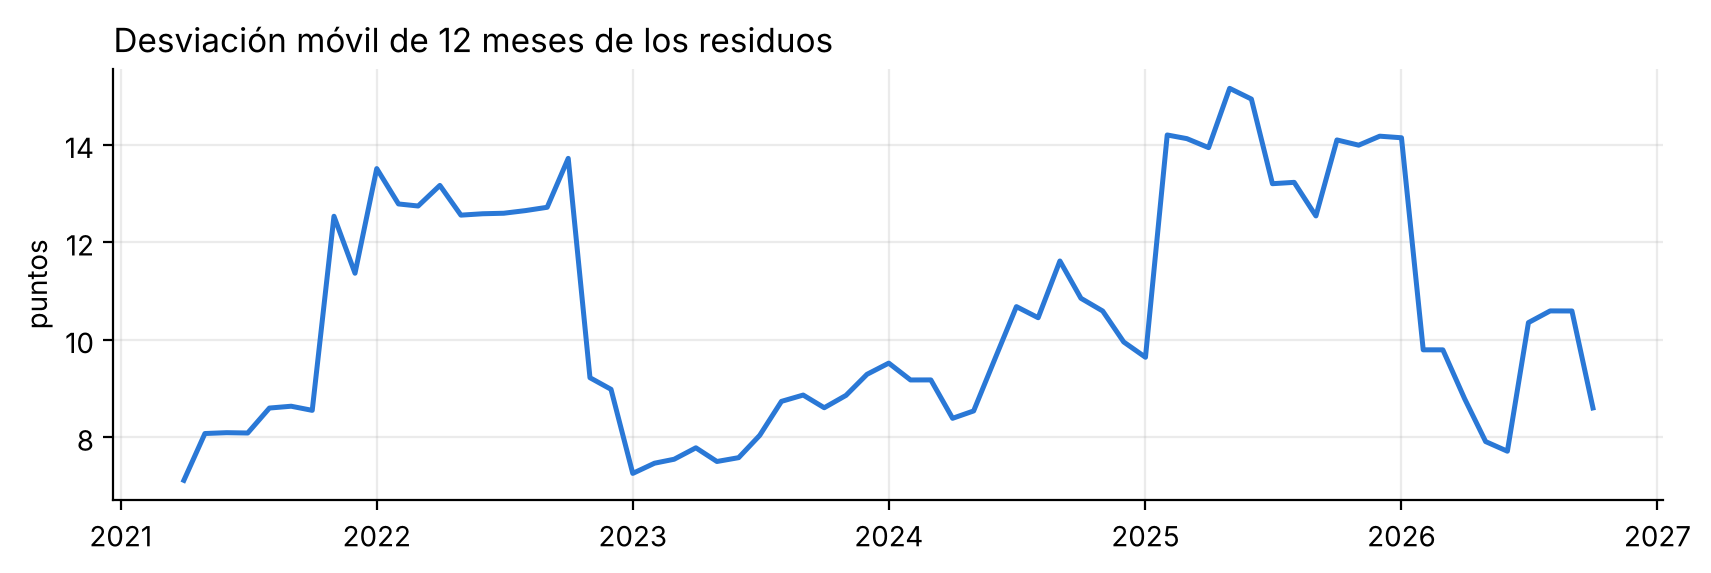

In [14]:
from statsmodels.stats.diagnostic import het_arch

arch_lm, arch_p, _, _ = het_arch(resid, nlags=6)
mitad = len(resid) // 2
lev = stats.levene(resid.iloc[:mitad], resid.iloc[mitad:])
print(f"ARCH (6 rezagos): LM = {arch_lm:.2f}, p = {arch_p:.3f}")
print(
    f"Levene: p = {lev.pvalue:.3f} · desviación 1.ª mitad {resid.iloc[:mitad].std():.2f}, "
    f"2.ª mitad {resid.iloc[mitad:].std():.2f}"
)

fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(resid.index, resid.rolling(12).std(), color=AZUL, lw=1.8)
ax.set_title("Desviación móvil de 12 meses de los residuos", loc="left")
ax.set_ylabel("puntos")
plt.show()

**Lectura.** Ninguna prueba rechaza (p = 0.66 y p = 0.51): **la varianza de los residuos es estable** y el intervalo de 95 % tiene el mismo significado en cualquier mes. La segunda mitad es un poco más volátil (11.2 contra 9.5 puntos), pero la diferencia no es significativa. Con esto, el modelo elegido cumple los dos requisitos: residuos **sin autocorrelación** (Ljung-Box p = 0.59) y con **varianza estable**.

**Lectura.** Si el p de Ljung-Box es > 0.05, no hay autocorrelación que quede sin explicar: el modelo aprovechó la estructura de la serie. Si Shapiro-Wilk rechaza la normalidad (colas pesadas por los picos de precio), el intervalo de 95 % es **aproximado**: puede quedarse corto en meses de crisis. (Los AIC de ETS y de ARIMA no se comparan entre sí porque usan verosimilitudes distintas; por eso la selección se hace por error de prueba.)

## 6. Pronóstico e intervalo de 95 %

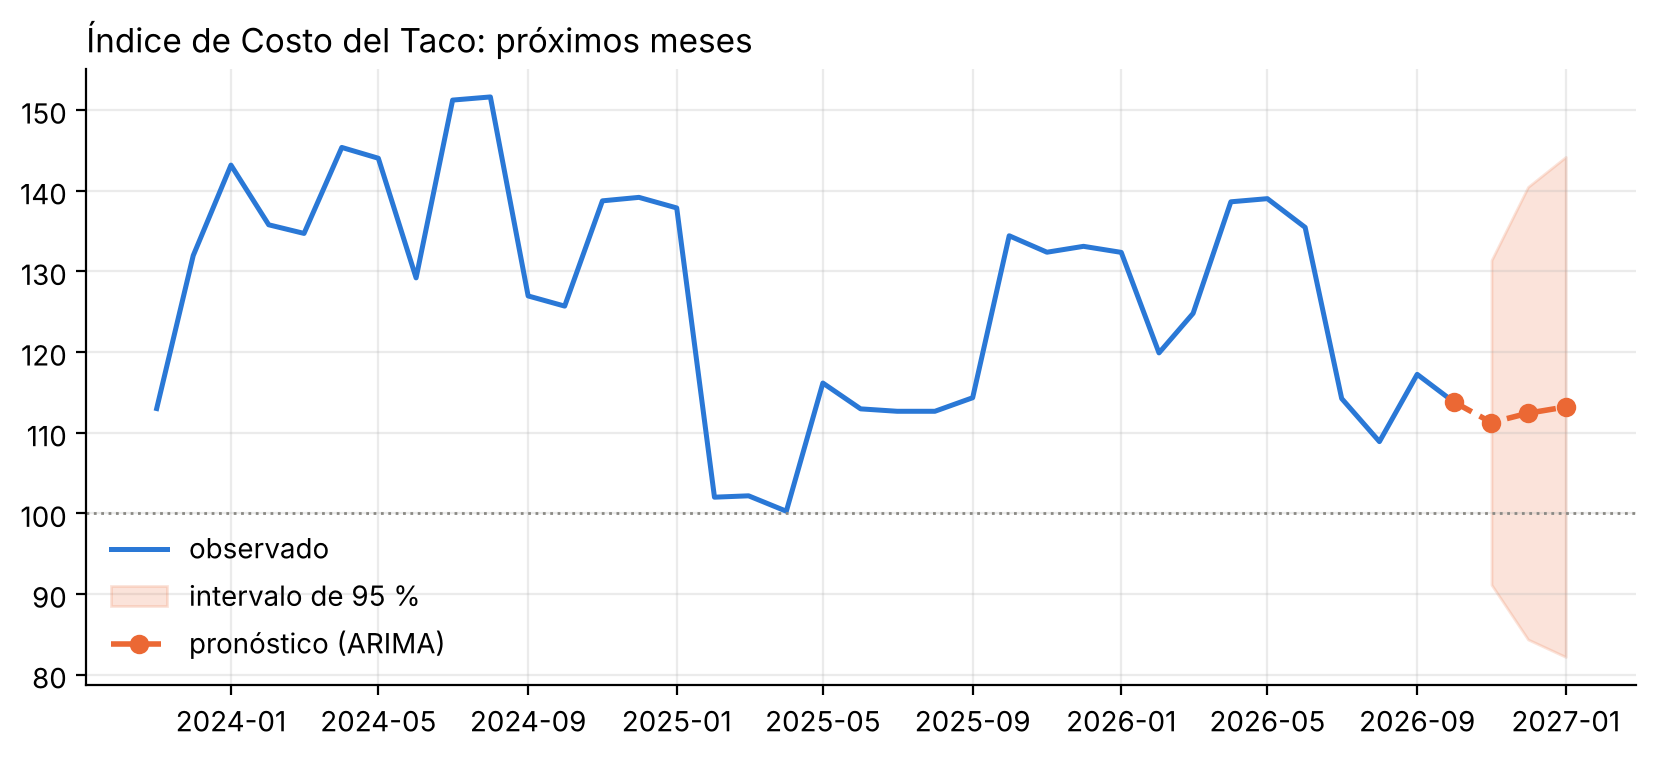

Último mes completo 2026-10: índice 113.8, canasta $238


,pronóstico,límite inferior 95 %,límite superior 95 %,costo aprox. de la canasta (MXN)
2026-11,111.3,91.2,131.4,233.0
2026-12,112.4,84.4,140.5,235.0
2027-01,113.2,82.2,144.2,237.0


In [15]:
futuro = pronosticar(modelo, HORIZONTE)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(serie.index[-36:], serie.iloc[-36:], color=AZUL, lw=1.8, label="observado")
ax.fill_between(futuro.index, futuro["li"], futuro["ls"], color=NARANJA, alpha=0.18, label="intervalo de 95 %")
ax.plot(
    [serie.index[-1], *futuro.index],
    [serie.iloc[-1], *futuro["valor"]],
    color=NARANJA,
    lw=2,
    ls="--",
    marker="o",
    label=f"pronóstico ({elegido})",
)
ax.axhline(100, color=GRIS, lw=1, ls=":")
ax.set_title("Índice de Costo del Taco: próximos meses", loc="left")
ax.legend(frameon=False, loc="lower left")
plt.show()

salida = futuro.round(1).rename(columns={"valor": "pronóstico", "li": "límite inferior 95 %", "ls": "límite superior 95 %"})
salida.index = salida.index.strftime("%Y-%m")
# Costo aproximado de 1 kg de cada insumo: se escala el costo del último mes completo con el cambio del índice
ult = indice.set_index("mes").loc[serie.index[-1].strftime("%Y-%m")]
salida["costo aprox. de la canasta (MXN)"] = (ult["costo_canasta_kg"] * salida["pronóstico"] / ult["indice"]).round(0)
print(f"Último mes completo {serie.index[-1]:%Y-%m}: índice {ult['indice']:.1f}, canasta ${ult['costo_canasta_kg']:.0f}")
salida

**Qué le decimos al taquero.**

* El valor central es la mejor estimación, pero el **intervalo es ancho**: los precios de frutas y verduras dependen del clima y el abasto, que ningún modelo con solo historia puede anticipar. El intervalo dice "en 95 de cada 100 meses parecidos, el índice cae aquí".
* Uso práctico: si el pronóstico **baja** y el intervalo superior queda cerca del nivel actual, es buen momento para una **promoción**; si el intervalo inferior queda arriba del nivel actual, conviene **cuidar el precio** del menú.
* El pronóstico se recalcula solo con cada captura (`pipeline/ejecutar.py` → `data/oro/pronostico.csv`), y el tablero muestra siempre el vigente junto con esta tabla de errores.

## 7. Conclusiones

1. La serie **no es estacionaria en nivel** (ADF p = 0.22, KPSS p = 0.01) y sí en primera diferencia (ADF p < 0.001): el mes pasado es el mejor punto de partida, y se usa d = 1.
2. El modelo de descomposición es **aditivo**: la amplitud no crece con el nivel (correlación −0.73). La **estacionalidad es prácticamente nula** (fuerza 0.00 contra 0.56 de la tendencia): Holt-Winters, el modelo con más parámetros, queda **último** fuera de muestra (RMSE 15.0) y es el único con residuos autocorrelacionados (Ljung-Box p = 0.04). Más complejidad no es más precisión.
3. Gana **ARIMA(2, 1, 0)**: RMSE 10.7 y MAPE 7.8 % en los 12 meses de prueba. SES y Holt tienen un MAE casi igual (9.34 contra 9.46), pero se equivocan más en los meses de salto, que son los que le cuestan al taquero y los que penaliza el RMSE. Además, ARIMA deja los residuos más limpios (Ljung-Box p = 0.59, sin autocorrelación; varianza estable: ARCH p = 0.66, Levene p = 0.51) y captura el rebote a 2 meses.
4. **Ningún modelo anticipó la caída de julio de 2026** (de ~135 a ~114): los cuatro pronósticos de prueba son casi planos, porque la serie se comporta casi como una caminata aleatoria con rebote. Lo honesto es comunicar el intervalo, no solo el valor central.
5. El intervalo de 95 % se abre de ±20 a ±31 puntos en tres meses: el pronóstico sirve para la **dirección** y el rango, no para un precio exacto.
6. **Limitaciones**: 79 meses de datos; meses imputados en 2020 y en la cebolla de 2021–2022 (probable MNAR, ver cuaderno de limpieza); los residuos están en el límite de la normalidad (Shapiro p = 0.06), así que el intervalo es aproximado. El pronóstico se recalcula cada día y estas cifras corresponden a la serie hasta octubre de 2026.